# Module 5: Regression Modeling, Cross-Validation & Residual Analysis

## Overview
In this module, we transition from the engineered feature set produced in **Module 4** (`X_train_selected.csv`, `y_train_log.csv`, and `X_test_selected.csv`) to predictive modeling, rigorous cross-validation, and diagnostic residual analysis.

### Key Objectives
1. **Model Training & Comparison:** Train and benchmark linear, regularized, and tree-based ensemble regressors:
   - Ordinary Least Squares (`LinearRegression`)
   - L2-Regularized (`Ridge`) & L1-Regularized (`Lasso`) Regression
   - Bagging Ensemble (`RandomForestRegressor`)
   - Gradient Boosted Decision Trees (`XGBRegressor` & `LGBMRegressor`)
2. **Multi-Metric K-Fold Cross-Validation:** Evaluate all models using **5-Fold Cross-Validation** across both log-transformed (`RMSE_log`, `R²_log`) and back-transformed dollar scales (`RMSE_USD`, `MAE_USD`, `MAPE %`, `R²_USD`).
3. **Residual & Error Diagnostics:** Inspect residual distributions, Q-Q plots, homoscedasticity, and quartile price-tier errors to check classical regression assumptions and uncover systematic under- or over-prediction.
4. **Test Set Inference:** Generate final `SalePrice` predictions on the unseen test set using the top-performing model.

In [1]:
import sys
import os
import warnings
warnings.filterwarnings("ignore")

# Add src directory to path to import custom modeling module
if "../src" not in sys.path:
    sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import modeling as mod

# Plotting configuration
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

print("Environment and custom `modeling` module loaded successfully.")

Environment and custom `modeling` module loaded successfully.


## 1. Load Engineered Feature Matrices from Module 4
We load the top-60 leak-free, VIF-filtered, and scaled features saved at the end of Module 4, along with the `log1p`-transformed target variable (`SalePrice`).

In [2]:
DATA_DIR = "../data/processed"

X_train_path = os.path.join(DATA_DIR, "X_train_selected.csv")
y_train_path = os.path.join(DATA_DIR, "y_train_log.csv")
X_test_path = os.path.join(DATA_DIR, "X_test_selected.csv")

if os.path.exists(X_train_path) and os.path.exists(y_train_path):
    X_train = pd.read_csv(X_train_path)
    y_train_log = pd.read_csv(y_train_path).squeeze()
    X_test = pd.read_csv(X_test_path) if os.path.exists(X_test_path) else None
    print(f"Loaded X_train: {X_train.shape} | y_train_log: {y_train_log.shape}")
    if X_test is not None:
        print(f"Loaded X_test:  {X_test.shape}")
else:
    raise FileNotFoundError(
        "Processed feature files not found in ../data/processed/. "
        "Please run Module 4 first to export X_train_selected.csv and y_train_log.csv."
    )

# Optional: load cleaned training set for contextual error slicing (e.g., Neighborhood, OverallQual)
train_cleaned_path = os.path.join(DATA_DIR, "train_cleaned.csv")
df_context = pd.read_csv(train_cleaned_path) if os.path.exists(train_cleaned_path) else None

Loaded X_train: (1458, 60) | y_train_log: (1458,)
Loaded X_test:  (1459, 60)


## 2. Candidate Regressors & 5-Fold Cross-Validation
We initialize six regression architectures spanning linear baselines, penalized linear models, bagging ensembles, and gradient boosted trees. Each model is evaluated via **5-Fold Cross-Validation** (`shuffle=True, random_state=42`).

To ensure accurate real-world interpretation, out-of-fold predictions $\hat{y}_{\log}$ are back-transformed via $\hat{y}_{\text{USD}} = \exp(\hat{y}_{\log}) - 1$ to compute dollar-denominated **RMSE**, **MAE**, **MAPE (%)**, and **$R^2$**.

In [3]:
# Initialize candidate models
models = mod.get_candidate_models(random_state=42)
print("Candidate Models Initialized:")
for idx, name in enumerate(models.keys(), 1):
    print(f"  {idx}. {name}")

# Execute 5-Fold Cross-Validation
summary_df, oof_predictions, fitted_models = mod.evaluate_models_cv(
    X=X_train,
    y_log=y_train_log,
    models=models,
    n_splits=5,
    random_state=42
)

# Display formatted benchmark table
display_cols = [
    "Model",
    "RMSE_log_Mean",
    "RMSE_log_Std",
    "R2_log_Mean",
    "RMSE_USD_Mean",
    "MAE_USD_Mean",
    "MAPE_pct_Mean",
    "R2_USD_Mean",
]
summary_styled = summary_df[display_cols].style.format({
    "RMSE_log_Mean": "{:.4f}",
    "RMSE_log_Std": "{:.4f}",
    "R2_log_Mean": "{:.4f}",
    "RMSE_USD_Mean": "${:,.2f}",
    "MAE_USD_Mean": "${:,.2f}",
    "MAPE_pct_Mean": "{:.2f}%",
    "R2_USD_Mean": "{:.4f}",
}).highlight_min(subset=["RMSE_log_Mean", "RMSE_USD_Mean", "MAE_USD_Mean", "MAPE_pct_Mean"], color="#d4edda")

summary_styled

Candidate Models Initialized:
  1. Linear Regression
  2. Ridge Regression (alpha=10)
  3. Lasso Regression (alpha=0.001)
  4. Random Forest
  5. XGBoost Regressor
  6. LightGBM Regressor


,Model,RMSE_log_Mean,RMSE_log_Std,R2_log_Mean,RMSE_USD_Mean,MAE_USD_Mean,MAPE_pct_Mean,R2_USD_Mean
0,XGBoost Regressor,0.1290,0.0070,0.8950,"$23,906.21","$15,787.70",9.25%,0.9090
1,Ridge Regression (alpha=10),0.1301,0.0072,0.8932,"$24,419.08","$16,587.08",9.65%,0.9049
2,Lasso Regression (alpha=0.001),0.1304,0.0068,0.8927,"$24,789.41","$16,659.30",9.65%,0.9022
3,Linear Regression,0.1306,0.0071,0.8922,"$24,296.49","$16,666.65",9.74%,0.9056
4,LightGBM Regressor,0.1320,0.0060,0.8902,"$25,071.16","$16,358.51",9.50%,0.9000
5,Random Forest,0.1448,0.0080,0.8674,"$28,765.51","$18,074.49",10.28%,0.8683


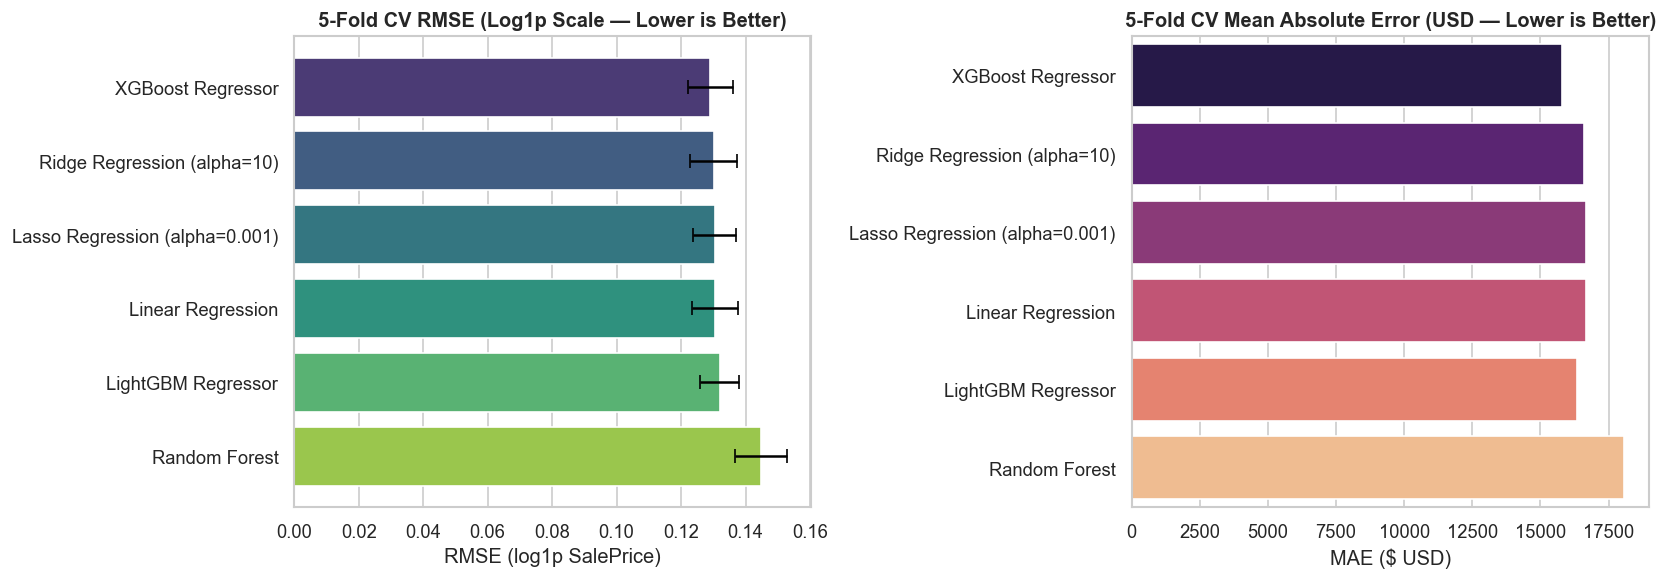

In [4]:
# Visualize Model Performance Comparison
os.makedirs("../reports/figures", exist_ok=True)
fig_comp = mod.plot_model_comparison(
    summary_df,
    save_path="../reports/figures/module5_model_comparison.png"
)
plt.show()

## 3. Residual Analysis & Assumption Verification
We select the top-performing model from cross-validation and examine its out-of-fold residuals ($e_i = y_i - \hat{y}_i$) to verify key regression diagnostics:
1. **Linearity & Homoscedasticity:** Residuals vs. predicted values should center horizontally around zero with constant variance across the price spectrum.
2. **Normality of Errors:** Standardized residuals should align closely with the theoretical normal line in the Q-Q plot (with minor tail deviations expected due to extreme luxury or distressed properties).
3. **Systematic Under/Over-Prediction:** Slicing dollar residuals across actual price quartiles (`Q1: Budget` to `Q4: Luxury`) reveals whether the model systematically under-prices high-end homes or over-prices entry-level homes.

In [5]:
# Identify best model based on lowest mean CV RMSE (log scale)
best_model_name = summary_df.loc[0, "Model"]
best_oof_log = oof_predictions[best_model_name]
print(f"Top-Performing Regressor: {best_model_name}")

# Compute row-level residuals and diagnostic statistics
res_df, diagnostics = mod.analyze_residuals(
    y_true_log=y_train_log,
    y_pred_log=best_oof_log,
    df_context=df_context
)

print("\n--- Residual Diagnostic Summary ---")
for k, v in diagnostics.items():
    if isinstance(v, dict):
        print(f"{k}:")
        for seg, val in v.items():
            print(f"    {seg}: ${val:,.2f}")
    elif isinstance(v, float):
        print(f"{k}: {v:.4f}")
    else:
        print(f"{k}: {v}")

Top-Performing Regressor: XGBoost Regressor

--- Residual Diagnostic Summary ---
Mean_Residual_Log: 0.0008
Std_Residual_Log: 0.1291
Mean_Residual_USD: 1918.5133
Median_Residual_USD: 1224.1951
Residual_Skewness: -1.0802
Residual_Kurtosis: 6.2843
Shapiro_Wilk_Stat: 0.9269
Shapiro_Wilk_p: 0.0000
Outliers_Beyond_3SD: 17
Segment_Mean_Bias_USD:
    Q1: Budget (<$130k): $-5,250.52
    Q2: Mid-Low: $384.11
    Q3: Mid-High: $171.36
    Q4: Luxury (>$214k): $12,459.94


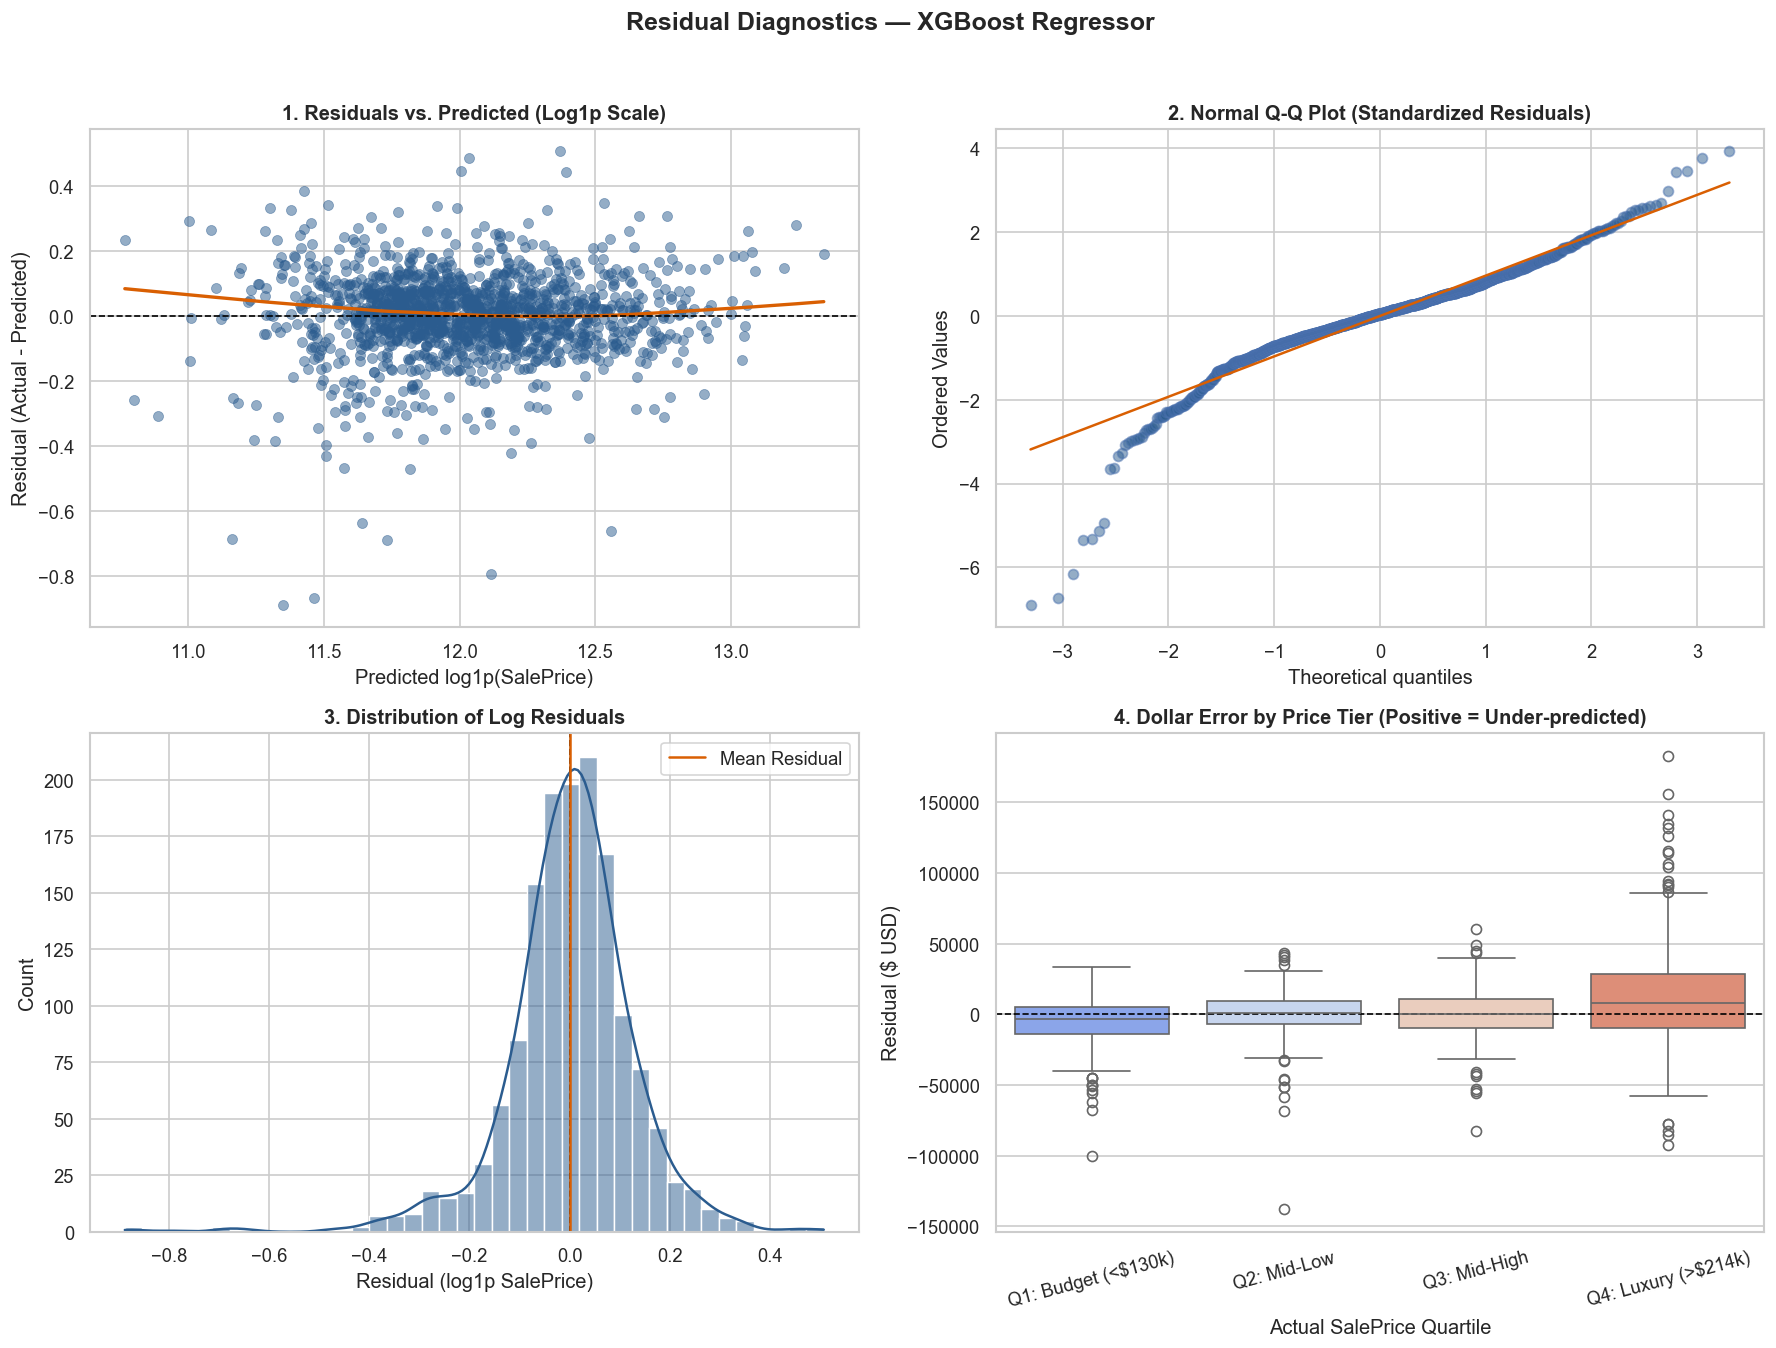

In [6]:
# Plot 4-Panel Residual Diagnostic Suite
fig_res = mod.plot_residual_diagnostics(
    res_df=res_df,
    model_name=best_model_name,
    save_path="../reports/figures/module5_residual_diagnostics.png"
)
plt.show()

### 3.1 Inspect Largest Prediction Errors (Outlier Audit)
Examining the top 10 largest absolute percentage errors helps identify atypical properties (e.g., partial sales, unusually large living areas sold at low prices, or historic estates) driving tail variance.

In [7]:
outlier_cols = ["Actual_USD", "Pred_USD", "Residual_USD", "Pct_Error", "Price_Segment"]
for extra in ["OverallQual", "GrLivArea", "Neighborhood"]:
    if extra in res_df.columns:
        outlier_cols.append(extra)

top_outliers = res_df.sort_values(by="Abs_Pct_Error", ascending=False).head(10)[outlier_cols]
top_outliers.style.format({
    "Actual_USD": "${:,.0f}",
    "Pred_USD": "${:,.0f}",
    "Residual_USD": "${:+,.0f}",
    "Pct_Error": "{:+.2f}%"
})

,Actual_USD,Pred_USD,Residual_USD,Pct_Error,Price_Segment,OverallQual,GrLivArea,Neighborhood
495,"$34,900","$84,876","$-49,976",-143.20%,Q1: Budget (<$130k),4,720,IDOTRR
30,"$40,000","$95,272","$-55,272",-138.18%,Q1: Budget (<$130k),4,1317,IDOTRR
631,"$82,500","$182,468","$-99,968",-121.17%,Q1: Budget (<$130k),7,1411,NWAmes
462,"$62,383","$124,383","$-62,000",-99.39%,Q1: Budget (<$130k),5,864,Sawyer
915,"$35,311","$70,216","$-34,905",-98.85%,Q1: Budget (<$130k),2,480,IDOTRR
1322,"$147,000","$284,763","$-137,763",-93.72%,Q2: Mid-Low,8,1795,Somerst
410,"$60,000","$113,568","$-53,568",-89.28%,Q1: Budget (<$130k),5,1276,Edwards
1451,"$84,500","$135,426","$-50,926",-60.27%,Q1: Budget (<$130k),5,1140,Mitchel
873,"$66,500","$106,303","$-39,803",-59.85%,Q1: Budget (<$130k),5,1131,OldTown
1430,"$64,500","$99,271","$-34,771",-53.91%,Q1: Budget (<$130k),4,968,OldTown


## 4. Feature Importance & Test Set Submission Export
Finally, we inspect the top predictive drivers learned by the best model and generate back-transformed `SalePrice` predictions on `X_test`.

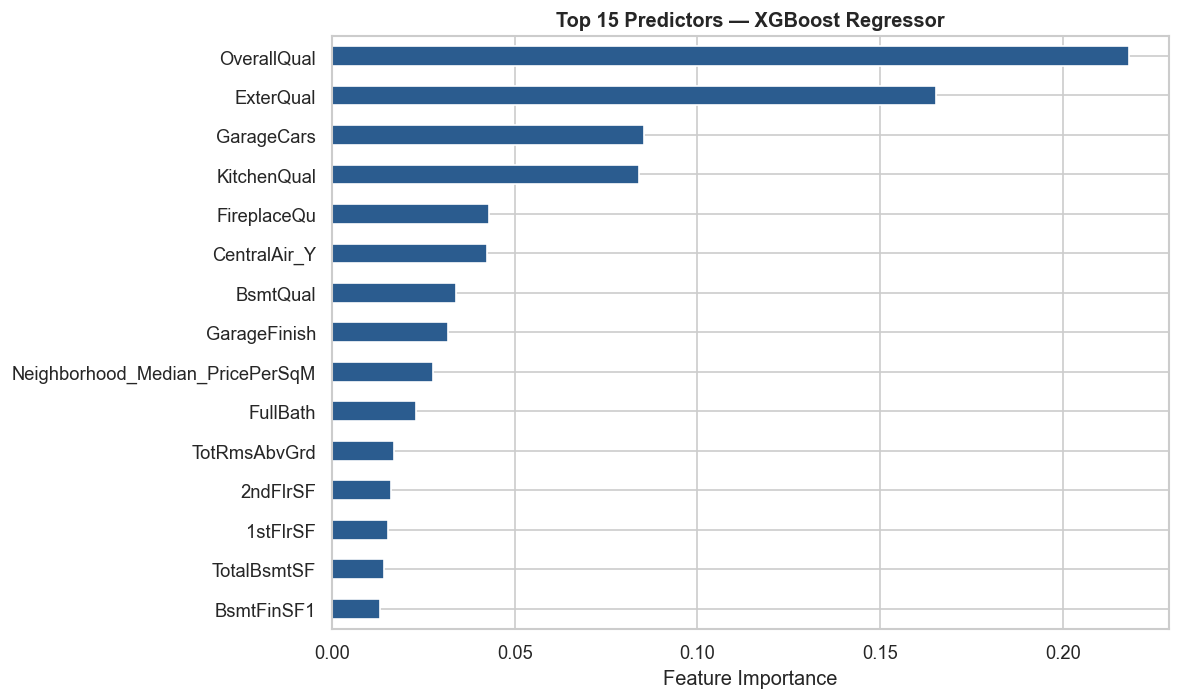

Saved 1459 test predictions to ../submissions/module5_predictions.csv


,Id,SalePrice
0,1461,117968.078125
1,1462,162056.671875
2,1463,178436.781250
3,1464,190080.578125
4,1465,186782.390625


In [8]:
best_estimator = fitted_models[best_model_name]

# Extract feature importances or absolute coefficients
if hasattr(best_estimator, "feature_importances_"):
    importances = pd.Series(best_estimator.feature_importances_, index=X_train.columns)
    imp_label = "Feature Importance"
elif hasattr(best_estimator, "coef_"):
    importances = pd.Series(np.abs(best_estimator.coef_), index=X_train.columns)
    imp_label = "Absolute Coefficient Magnitude"
else:
    importances = None

if importances is not None:
    top_15_imp = importances.sort_values(ascending=True).tail(15)
    fig, ax = plt.subplots(figsize=(10, 6))
    top_15_imp.plot(kind="barh", color="#2b5c8f", ax=ax)
    ax.set_title(f"Top 15 Predictors — {best_model_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel(imp_label)
    plt.tight_layout()
    plt.show()

# Generate test set predictions if X_test is available
if X_test is not None:
    test_pred_log = best_estimator.predict(X_test)
    test_pred_usd = np.expm1(test_pred_log)

    # Align IDs if test_cleaned.csv is present
    test_cleaned_path = os.path.join(DATA_DIR, "test_cleaned.csv")
    if os.path.exists(test_cleaned_path) and "Id" in pd.read_csv(test_cleaned_path, usecols=["Id"]).columns:
        test_ids = pd.read_csv(test_cleaned_path)["Id"]
    else:
        test_ids = np.arange(1461, 1461 + len(X_test))

    submission = pd.DataFrame({
        "Id": test_ids,
        "SalePrice": test_pred_usd
    })
    os.makedirs("../submissions", exist_ok=True)
    sub_path = "../submissions/module5_predictions.csv"
    submission.to_csv(sub_path, index=False)
    print(f"Saved {len(submission)} test predictions to {sub_path}")
    display(submission.head())